In [1]:
import os
import shutil
import sklearn
print('The scikit-learn version is {}.'.format(sklearn.__version__))
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer
from sklearn.linear_model import SGDClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import multilabel_confusion_matrix
import numpy as np
import pandas as pd
from shutil import copy2 
import joblib
import json
from collections import Counter
import matplotlib.pyplot as plt


The scikit-learn version is 1.0.2.


In [16]:


##INPUT FILES HERE ##
#training set
training_set = [os.path.join("/home/javi/git/bsc/debbie/Classifier/classifier-development/trainning_set", f) for f in os.listdir("/home/javi/git/bsc/debbie/Classifier/classifier-development/trainning_set")]

#test_set 
test_set = [os.path.join("/home/javi/git/bsc/debbie/Classifier/classifier-development/test_set", f) for f in os.listdir("/home/javi/git/bsc/debbie/Classifier/classifier-development/test_set")]

#clarence dataset

#training set
#training_set = [os.path.join("/home/javi/git/bsc/debbie/Classifier/classifier-development/clarence-dataset/training-set/abstracts", f) for f in os.listdir("/home/javi/git/bsc/debbie/Classifier/classifier-development/clarence-dataset/training-set/abstracts")]

#test_set 
#test_set = [os.path.join("/home/javi/git/bsc/debbie/Classifier/classifier-development/clarence-dataset/testing-set/abstracts", f) for f in os.listdir("/home/javi/git/bsc/debbie/Classifier/classifier-development/clarence-dataset/testing-set/abstracts")]



In [17]:
#making labels 
def make_labels(data):
    files = data
    file_list = []
    train_labels = [None] * (len(files))
    count = 0
    docID = 0
    for fil in files:
        file_list.append(fil)
        train_labels[docID] = 'non-relevant'
        filepathTokens = fil.split('/')
        lastToken = filepathTokens[len(filepathTokens) - 1]
        if fil.endswith("_clinical.txt"):
            train_labels[docID] = 'clinical'
            count = count + 1
        elif fil.endswith("_non-clinical.txt"):
            train_labels[docID] = 'non-clinical'
            count = count + 1
        docID = docID + 1
    combined_labels_files = dict(zip(train_labels, file_list))
    #print (train_labels)
    #print (file_list)
    print (combined_labels_files)
    return train_labels, file_list, combined_labels_files
    

#make labels for multiclass training and test set
training_set_labels, file_list, combined_training = make_labels(training_set)
test_set_labels, test_file_list, combined_testing  = make_labels(test_set)

{'non-clinical': '/home/javi/git/bsc/debbie/Classifier/classifier-development/trainning_set/27377439_non-clinical.txt', 'non-relevant': '/home/javi/git/bsc/debbie/Classifier/classifier-development/trainning_set/18967084_background.txt', 'clinical': '/home/javi/git/bsc/debbie/Classifier/classifier-development/trainning_set/24379328_clinical.txt'}
{'non-clinical': '/home/javi/git/bsc/debbie/Classifier/classifier-development/test_set/25668049_non-clinical.txt', 'clinical': '/home/javi/git/bsc/debbie/Classifier/classifier-development/test_set/24396842_clinical.txt', 'non-relevant': '/home/javi/git/bsc/debbie/Classifier/classifier-development/test_set/28061532_background.txt'}


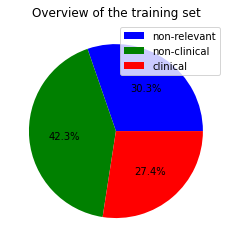

In [18]:
# to represent the distribution of the training set in a circular diagram


labels = ['non-relevant','non-clinical','clinical']

sizes = list(dict(Counter(training_set_labels)).values())
colours = {'non-relevant':'b','non-clinical':'g','clinical':'r'}
plt.pie(sizes,colors=[colours[key] for key in labels],autopct='%1.1f%%')
plt.legend(labels)
plt.title('Overview of the training set')
plt.show()

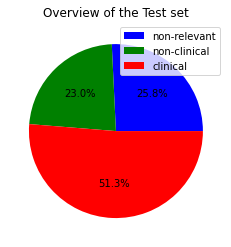

In [19]:
# to represent the distribution of the test:


labels = ['non-relevant','non-clinical','clinical']

sizes = list(dict(Counter(test_set_labels)).values())
colours = {'non-relevant':'b','non-clinical':'g','clinical':'r'}
plt.pie(sizes,colors=[colours[key] for key in labels],autopct='%1.1f%%')
plt.legend(labels)
plt.title('Overview of the Test set')
plt.show()

In [20]:
##make a dictionary from the training set:
count_vect = CountVectorizer(input='filename', ngram_range=(1,2), max_df=0.9, min_df=0.0, stop_words= 'english') #decode_error='ignore' input='filename', encoding='cp850'
X_train_counts = count_vect.fit_transform(training_set)

#tf_idf calculation for the words in the training_set
tf_transformer = TfidfTransformer(use_idf= False).fit(X_train_counts)
X_train_tf = tf_transformer.transform(X_train_counts)
tfidf_transformer = TfidfTransformer()
X_train_tfidf  = tfidf_transformer.fit_transform(X_train_counts)

#bag of word and tf_idf of test set
X_test_count = count_vect.transform(test_set)
X_test_tfidf = tfidf_transformer.transform(X_test_count)


In [24]:
#train and test the the model

#option I: SGD muticlass
sgd_clf = SGDClassifier(loss= 'log', penalty= 'l2').fit(X_train_tfidf, training_set_labels)
#Deprecated since version 1.1: The loss ‘log’ was deprecated in v1.1 and will be removed in version 1.3. 
#Use loss='log_loss' which is equivalent.
#sgd_clf = SGDClassifier(loss= 'log', penalty= 'l2').fit(X_train_tfidf, training_set_labels)

#test the model
predicted = sgd_clf.predict(X_test_tfidf)

#the results of the classification
results = dict(zip(test_set, predicted))


df_results = pd.DataFrame.from_dict(results, orient='index')


In [25]:
#add line specifying study type for relevant studies

relevant_abstracts = []
not_relevant_abstracts = []

for key, value in results.items():
    if value == 'clinical':
        relevant_abstracts.append(key)
        with open (key, 'r+') as f:
            content = f.read()
            f.seek(0, 0)
            f.write('study type= clinical (classifier)' + '\n' + content)
            copy2(key, '/home/osnat/Desktop/with_study_type')
    elif value == 'non-clinical':
        relevant_abstracts.append(key)
        with open (key, 'r+') as f:
            content = f.read()
            f.seek(0, 0)
            f.write('study type= non-clinical (classifier)' + '\n' + content)
            copy2(key, '/home/osnat/Desktop/with_study_type')
    else:
        not_relevant_abstracts.append(key)

FileNotFoundError: [Errno 2] No such file or directory: '/home/osnat/Desktop/with_study_type'

In [26]:
 # check performance
    
from sklearn.metrics import precision_recall_fscore_support as score

precision, recall, fscore, support = score(test_set_labels, predicted, average='weighted')

df = pd.DataFrame(columns=['model','batch name','precision', 'recall' , 'F1'])
performance = ['multiclass SGD', ]

performance.append('binary')
performance.append(precision)
performance.append(recall)
performance.append(fscore)

df.loc[len(df)] = performance
print(df)

# if need to save runs:
#df.to_csv('test_scores.csv',sep=' ', index=False, header=False, mode='a')

            model batch name  precision  recall        F1
0  multiclass SGD     binary    0.88993  0.8728  0.875232


In [27]:
#create trained and compressed model
joblib.dump(sgd_clf, 'svm_model.pkl', compress=9)
joblib.dump(count_vect, 'count_vect.pkl', compress=9)
joblib.dump(tfidf_transformer, 'transformer.pkl', compress=9)

['transformer.pkl']